In [8]:
import pandas as pd

In [12]:
df = pd.read_csv("/content/superstore_sales.csv")
print(df.shape)

(9800, 18)


In [14]:
print(df.shape)

(9800, 18)


In [16]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [20]:
print(df.isnull().sum())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [22]:
print(df.duplicated().sum())


0


In [24]:
df[df['Postal Code'].isnull()][["Order ID", "City", "State", "Postal Code"]]

,Order ID,City,State,Postal Code
2234,CA-2018-104066,Burlington,Vermont,NaN
5274,CA-2016-162887,Burlington,Vermont,NaN
8798,US-2017-150140,Burlington,Vermont,NaN
9146,US-2017-165505,Burlington,Vermont,NaN
9147,US-2017-165505,Burlington,Vermont,NaN
9148,US-2017-165505,Burlington,Vermont,NaN
9386,US-2018-127292,Burlington,Vermont,NaN
9387,US-2018-127292,Burlington,Vermont,NaN
9388,US-2018-127292,Burlington,Vermont,NaN
9389,US-2018-127292,Burlington,Vermont,NaN


In [26]:
df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,08/11/2017,11/11/2017
1,08/11/2017,11/11/2017
2,12/06/2017,16/06/2017
3,11/10/2016,18/10/2016
4,11/10/2016,18/10/2016


In [28]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d/%m/%Y")

In [30]:
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d/%m/%Y")

In [32]:
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [35]:
# 1. Fill the missing values
df.loc[df["Postal Code"].isnull(), "Postal Code"] = 5401

In [37]:
# 2. Convert Postal Code to text with 5 digits
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

In [41]:
# 3. Check
print(df["Postal Code"].isnull().sum())
print(df[df["City"] == "Burlington"]["Postal Code"].unique())

0
['27217' '52601' '05401']


In [42]:
df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


In [44]:
# 1. Order Year: pull the year out of the Order Date (e.g. 2017)
df["Order Year"] = df["Order Date"].dt.year


In [45]:
# 2. Order Month: month as a number from 1 to 12 (useful for sorting)
df["Order Month"] = df["Order Date"].dt.month


In [46]:
# 3. Month Name: month as short text like Jan, Feb, Mar (useful for chart labels)
df["Month Name"] = df["Order Date"].dt.strftime("%b")


In [47]:
# 4. Shipping Days: days between ordering and shipping
#    Ship Date - Order Date gives a "timedelta", and .dt.days turns it into a plain number
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days


In [48]:
# 5. Check the new columns
df[["Order Date", "Order Year", "Order Month", "Month Name", "Ship Date", "Shipping Days"]].head()

,Order Date,Order Year,Order Month,Month Name,Ship Date,Shipping Days
0,2017-11-08,2017,11,Nov,2017-11-11,3
1,2017-11-08,2017,11,Nov,2017-11-11,3
2,2017-06-12,2017,6,Jun,2017-06-16,4
3,2016-10-11,2016,10,Oct,2016-10-18,7
4,2016-10-11,2016,10,Oct,2016-10-18,7


In [49]:
df.to_csv("/content/superstore_clean.csv", index=False)

In [50]:
print(df["Shipping Days"].min(), df["Shipping Days"].max())
print((df["Ship Date"] < df["Order Date"]).sum())

0 7
0


In [51]:
df.to_csv("/content/superstore_clean.csv", index=False)


In [52]:
# Total sales for each month number, in calendar order
monthly = df.groupby(["Order Month", "Month Name"])["Sales"].sum().reset_index()

# Show highest and lowest
print("Highest:", monthly.loc[monthly["Sales"].idxmax()].to_dict())
print("Lowest:", monthly.loc[monthly["Sales"].idxmin()].to_dict())

monthly

Highest: {'Order Month': 11, 'Month Name': 'Nov', 'Sales': 350161.711}
Lowest: {'Order Month': 2, 'Month Name': 'Feb', 'Sales': 59371.1154}


,Order Month,Month Name,Sales
0,1,Jan,94291.6296
1,2,Feb,59371.1154
2,3,Mar,197573.5872
3,4,Apr,136283.0006
4,5,May,154086.7237
5,6,Jun,145837.5233
6,7,Jul,145535.6890
7,8,Aug,157315.9270
8,9,Sep,300103.4117
9,10,Oct,199496.2947


In [53]:
# Rows = months, columns = years
pivot = df.pivot_table(values="Sales", index="Order Month", columns="Order Year", aggfunc="sum")
pivot.round(0)

Order Year,2015,2016,2017,2018
Order Month,,,,
1,14206.0,18067.0,18542.0,43476.0
2,4520.0,11951.0,22979.0,19921.0
3,55206.0,32339.0,51165.0,58863.0
4,27907.0,34154.0,38680.0,35542.0
5,23644.0,29960.0,56657.0,43826.0
6,34323.0,23599.0,39724.0,48191.0
7,33782.0,28608.0,38321.0,44825.0
8,27118.0,36818.0,30542.0,62838.0
9,81624.0,63134.0,69193.0,86153.0


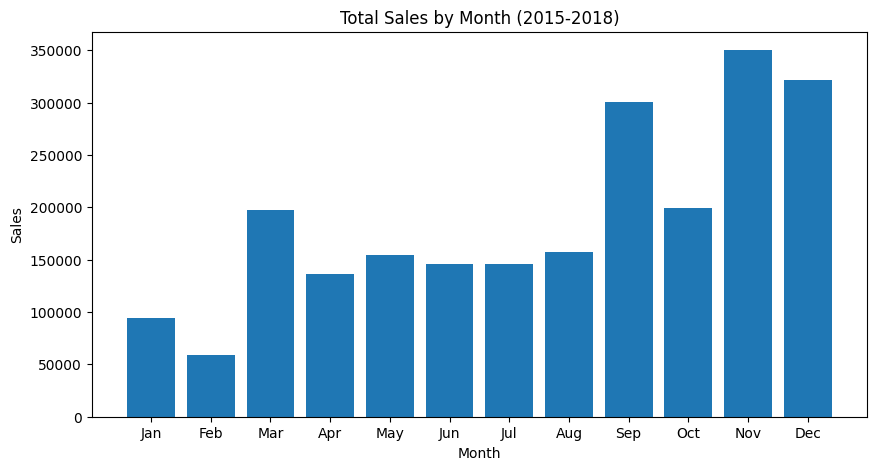

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(monthly["Month Name"], monthly["Sales"])
plt.title("Total Sales by Month (2015-2018)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

In [55]:
print(df.groupby("Order Year")["Order Month"].nunique())

Order Year
2015    12
2016    12
2017    12
2018    12
Name: Order Month, dtype: int64


In [56]:
# Total sales per category, highest first
cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False).round(0)

# Share of total sales (%)
cat_pct = (cat / cat.sum() * 100).round(1)

print(cat)
print(cat_pct)

Category
Technology         827456.0
Furniture          728659.0
Office Supplies    705422.0
Name: Sales, dtype: float64
Category
Technology         36.6
Furniture          32.2
Office Supplies    31.2
Name: Sales, dtype: float64


In [57]:
sub = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).round(0)
sub

,Sales
Sub-Category,
Phones,327782.0
Chairs,322823.0
Storage,219343.0
Tables,202811.0
Binders,200029.0
Machines,189239.0
Accessories,164187.0
Copiers,146248.0
Bookcases,113813.0


In [58]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .round(0)
)
top_products

,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61600.0
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.0
Cisco TelePresence System EX90 Videoconferencing Unit,22638.0
HON 5400 Series Task Chairs for Big and Tall,21871.0
GBC DocuBind TL300 Electric Binding System,19823.0
GBC Ibimaster 500 Manual ProClick Binding System,19024.0
Hewlett Packard LaserJet 3310 Copier,18840.0
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18375.0
GBC DocuBind P400 Electric Binding System,17965.0


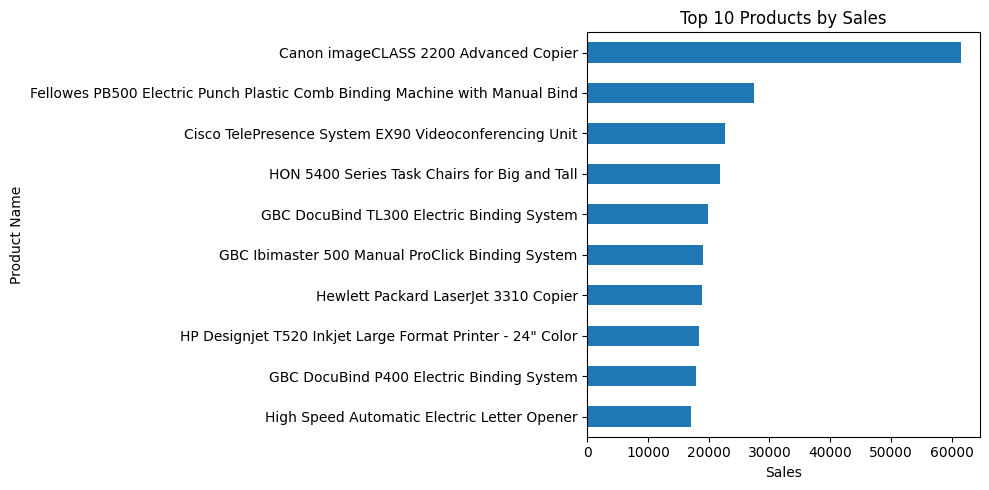

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")   # sort so the biggest bar is on top
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

In [61]:
print(df["Product Name"].nunique(), df["Product ID"].nunique())

1849 1861


In [62]:
# Count how many different IDs each product name has
ids_per_name = df.groupby("Product Name")["Product ID"].nunique()

# Keep only names that have more than 1 ID
dup_names = ids_per_name[ids_per_name > 1]
print(len(dup_names))
dup_names

16


,Product ID
Product Name,
"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",2
Avery Non-Stick Binders,2
Easy-staple paper,8
Eldon Wave Desk Accessories,2
KI Adjustable-Height Table,2
Okidata C610n Printer,2
"Peel & Seel Recycled Catalog Envelopes, Brown",2
Prang Drawing Pencil Set,2
Staple envelope,9


In [63]:
# Pick the first duplicate name and see its rows
name = dup_names.index[0]
df[df["Product Name"] == name][["Product ID", "Product Name", "Category", "Sub-Category", "Sales"]].drop_duplicates()

,Product ID,Product Name,Category,Sub-Category,Sales
985,OFF-EN-10000461,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,27.968
1989,OFF-EN-10000781,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,26.220
2446,OFF-EN-10000461,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,17.480
2948,OFF-EN-10000461,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,43.700
4992,OFF-EN-10000461,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,55.936
5688,OFF-EN-10000781,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,48.944
6301,OFF-EN-10000461,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",Office Supplies,Envelopes,13.984


In [65]:
# Any product name that appears in more than one category or sub-category?
check = df.groupby("Product Name")[["Category", "Sub-Category"]].nunique()
print((check > 1).sum())

Category        0
Sub-Category    0
dtype: int64


In [66]:
cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False).round(0)
print(cat, (cat / cat.sum() * 100).round(1))

sub = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).round(0)
print(sub)

top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10).round(0)
print(top_products)

Category
Technology         827456.0
Furniture          728659.0
Office Supplies    705422.0
Name: Sales, dtype: float64 Category
Technology         36.6
Furniture          32.2
Office Supplies    31.2
Name: Sales, dtype: float64
Sub-Category
Phones         327782.0
Chairs         322823.0
Storage        219343.0
Tables         202811.0
Binders        200029.0
Machines       189239.0
Accessories    164187.0
Copiers        146248.0
Bookcases      113813.0
Appliances     104618.0
Furnishings     89212.0
Paper           76828.0
Supplies        46420.0
Art             26705.0
Envelopes       16128.0
Labels          12348.0
Fasteners        3002.0
Name: Sales, dtype: float64
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61600.0
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.0
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.0
HON 5400 Series Task Chairs for Big and Tall   

In [67]:
# Did the duplicate names cross categories? Expect 0 and 0
check = df.groupby("Product Name")[["Category", "Sub-Category"]].nunique()
print((check > 1).sum())

# Share of the top 10 products in total sales
print((top_products.sum() / df["Sales"].sum() * 100).round(1))

Category        0
Sub-Category    0
dtype: int64
10.8


In [68]:
# Technology sales per state, highest first
tech_state = (
    df[df["Category"] == "Technology"]
    .groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .round(0)
)
tech_state.head(10)

,Sales
State,
California,154684.0
New York,126903.0
Texas,64656.0
Washington,50537.0
Florida,46968.0
Pennsylvania,42064.0
Ohio,34551.0
Illinois,31638.0
North Carolina,26083.0


In [70]:
# Rows = states, columns = categories
state_cat = df.pivot_table(values="Sales", index="State", columns="Category", aggfunc="sum", fill_value=0)

# For each state, which category has the highest sales?
state_cat["Leading Category"] = state_cat[["Furniture", "Office Supplies", "Technology"]].idxmax(axis=1)

# States where Technology is the leader
tech_leads = state_cat[state_cat["Leading Category"] == "Technology"]
print(len(tech_leads), "states where Technology leads")
tech_leads.sort_values("Technology", ascending=False).round(0).head(10)

20 states where Technology leads


Category,Furniture,Office Supplies,Technology,Leading Category
State,,,,
California,152217.0,139406.0,154684.0,Technology
New York,92505.0,86954.0,126903.0,Technology
Texas,59634.0,44283.0,64656.0,Technology
Washington,44626.0,40044.0,50537.0,Technology
Florida,22743.0,18725.0,46968.0,Technology
Pennsylvania,39355.0,34858.0,42064.0,Technology
Ohio,23251.0,17329.0,34551.0,Technology
Illinois,28213.0,19386.0,31638.0,Technology
North Carolina,14718.0,14365.0,26083.0,Technology


In [71]:
state_cat["Leading Category"].value_counts()

,count
Leading Category,
Technology,20
Furniture,15
Office Supplies,14


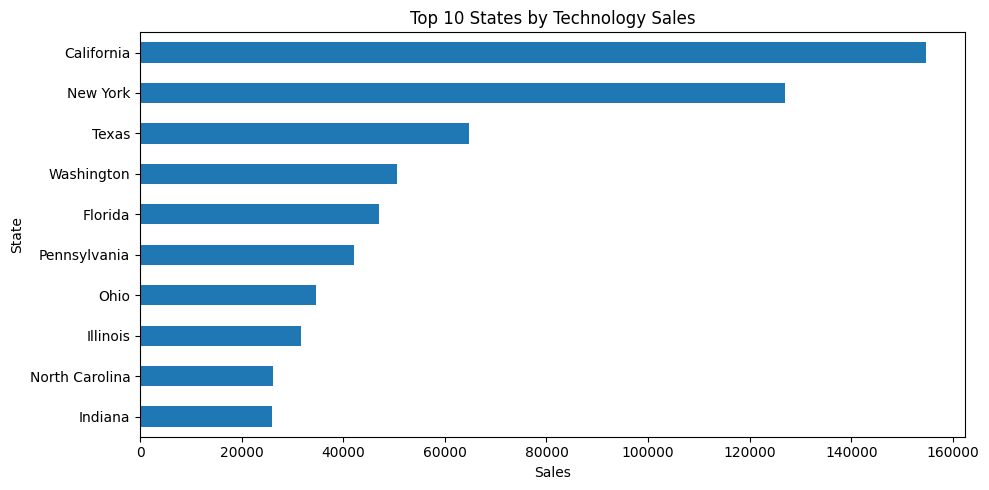

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
tech_state.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 States by Technology Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

In [73]:
print(df.groupby("State")["Order ID"].nunique().sort_values().head(10))

State
Wyoming                  1
North Dakota             2
West Virginia            2
Maine                    3
District of Columbia     4
South Dakota             5
Vermont                  6
Montana                  8
Idaho                   11
Kansas                  14
Name: Order ID, dtype: int64


In [74]:
# Count orders per state
orders_per_state = df.groupby("State")["Order ID"].nunique()

# Keep only states with 30+ orders
big_states = orders_per_state[orders_per_state >= 30].index
print(len(big_states), "states pass the filter")

# Redo the leading-category result for those states only
reliable = state_cat.loc[state_cat.index.isin(big_states)]
print(reliable["Leading Category"].value_counts())

reliable[reliable["Leading Category"] == "Technology"].sort_values("Technology", ascending=False).round(0)

28 states pass the filter
Leading Category
Technology         14
Furniture           7
Office Supplies     7
Name: count, dtype: int64


Category,Furniture,Office Supplies,Technology,Leading Category
State,,,,
California,152217.0,139406.0,154684.0,Technology
New York,92505.0,86954.0,126903.0,Technology
Texas,59634.0,44283.0,64656.0,Technology
Washington,44626.0,40044.0,50537.0,Technology
Florida,22743.0,18725.0,46968.0,Technology
Pennsylvania,39355.0,34858.0,42064.0,Technology
Ohio,23251.0,17329.0,34551.0,Technology
Illinois,28213.0,19386.0,31638.0,Technology
North Carolina,14718.0,14365.0,26083.0,Technology


In [75]:
# A. How often each category appears in orders
freq = df.groupby("Category").agg(
    order_lines=("Row ID", "count"),
    unique_orders=("Order ID", "nunique"),
    unique_customers=("Customer ID", "nunique")
)
print(freq)

# B. Repeat buying: customers who bought the category in 2+ different orders
cust_cat = df.groupby(["Category", "Customer ID"])["Order ID"].nunique().reset_index(name="orders")
repeat_customers = cust_cat[cust_cat["orders"] >= 2].groupby("Category").size()
all_customers = cust_cat.groupby("Category").size()
print((repeat_customers / all_customers * 100).round(1))   # % of customers who repeat

# C. Same idea at sub-category level (top 10 by number of orders)
df.groupby("Sub-Category")["Order ID"].nunique().sort_values(ascending=False).head(10)

                 order_lines  unique_orders  unique_customers
Category                                                     
Furniture               2078           1727               705
Office Supplies         5909           3676               787
Technology              1813           1519               684
Category
Furniture          72.1
Office Supplies    95.6
Technology         64.6
dtype: float64


,Order ID
Sub-Category,
Binders,1291
Paper,1163
Furnishings,855
Phones,803
Storage,764
Art,720
Accessories,702
Chairs,566
Appliances,444


In [76]:
# Average, median and maximum shipping days per category
df.groupby("Category")["Shipping Days"].agg(["mean", "median", "max"]).round(2)

# Does Ship Mode matter more than Category?
df.pivot_table(values="Shipping Days", index="Category", columns="Ship Mode", aggfunc="mean").round(2)

# Ship Mode alone
df.groupby("Ship Mode")["Shipping Days"].mean().round(2)

,Shipping Days
Ship Mode,
First Class,2.18
Same Day,0.04
Second Class,3.25
Standard Class,5.01


In [77]:
df.groupby("Category")["Shipping Days"].agg(["mean", "median", "max"]).round(2)
df.pivot_table(values="Shipping Days", index="Category", columns="Ship Mode", aggfunc="mean").round(2)

Ship Mode,First Class,Same Day,Second Class,Standard Class
Category,,,,
Furniture,2.14,0.03,3.28,4.98
Office Supplies,2.20,0.05,3.22,5.02
Technology,2.16,0.05,3.30,4.98


In [79]:
print(df["Ship Mode"].value_counts(normalize=True).mul(100).round(1))

Ship Mode
Standard Class    59.8
Second Class      19.4
First Class       15.3
Same Day           5.5
Name: proportion, dtype: float64


In [80]:
df.groupby("Category")["Shipping Days"].agg(["mean", "median", "max"]).round(2)

,mean,median,max
Category,,,
Furniture,3.93,4.0,7
Office Supplies,3.98,4.0,7
Technology,3.92,4.0,7


In [82]:
sales = df.groupby("Category")["Sales"].sum()
orders = df.groupby("Category")["Order ID"].nunique()
print((sales / orders).round(0))

Category
Furniture          422.0
Office Supplies    192.0
Technology         545.0
dtype: float64


In [83]:
pivot = df.pivot_table(values="Sales", index="Order Month", columns="Order Year", aggfunc="sum")
print(pivot.round(0))

print(pivot.idxmax())   # highest month in each year
print(pivot.idxmin())   # lowest month in each year

Order Year      2015     2016     2017      2018
Order Month                                     
1            14206.0  18067.0  18542.0   43476.0
2             4520.0  11951.0  22979.0   19921.0
3            55206.0  32339.0  51165.0   58863.0
4            27907.0  34154.0  38680.0   35542.0
5            23644.0  29960.0  56657.0   43826.0
6            34323.0  23599.0  39724.0   48191.0
7            33782.0  28608.0  38321.0   44825.0
8            27118.0  36818.0  30542.0   62838.0
9            81624.0  63134.0  69193.0   86153.0
10           31453.0  31012.0  59583.0   77448.0
11           77908.0  75249.0  79066.0  117938.0
12           68167.0  74544.0  95739.0   83030.0
Order Year
2015     9
2016    11
2017    12
2018    11
dtype: int32
Order Year
2015    2
2016    2
2017    1
2018    2
dtype: int32


In [84]:
yearly = df.groupby("Order Year")["Sales"].sum().round(0)
print(yearly)
print((yearly.pct_change() * 100).round(1))

Order Year
2015    479856.0
2016    459436.0
2017    600193.0
2018    722052.0
Name: Sales, dtype: float64
Order Year
2015     NaN
2016    -4.3
2017    30.6
2018    20.3
Name: Sales, dtype: float64


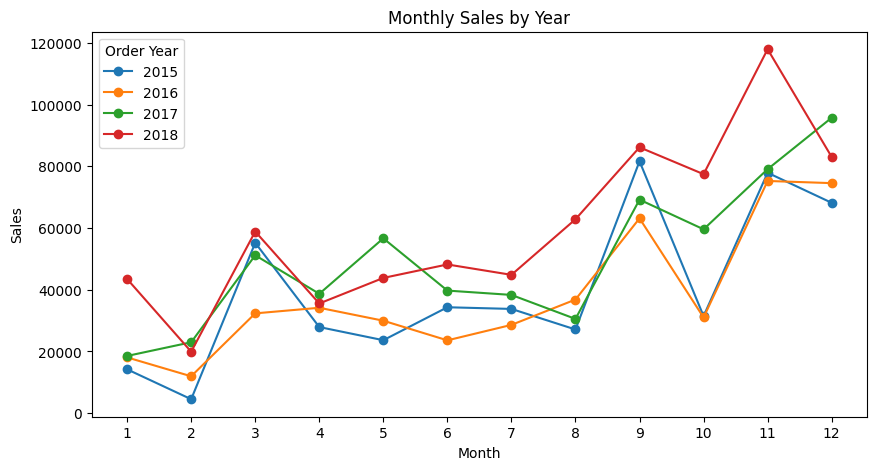

In [85]:
import matplotlib.pyplot as plt

pivot.plot(figsize=(10, 5), marker="o")
plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.show()

In [86]:
df.to_csv("/content/superstore_clean.csv", index=False)

Order Year
2015    479856.0
2016    459436.0
2017    600193.0
2018    722052.0
Name: Sales, dtype: float64
Order Year
2015     NaN
2016    -4.3
2017    30.6
2018    20.3
Name: Sales, dtype: float64


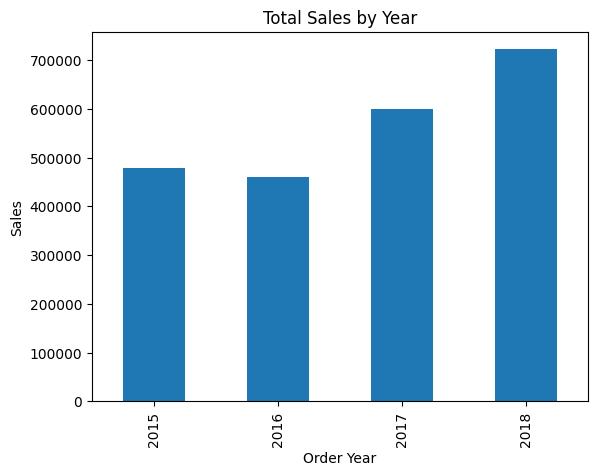

In [87]:
import matplotlib.pyplot as plt

yearly = df.groupby("Order Year")["Sales"].sum().round(0)
print(yearly)
print((yearly.pct_change() * 100).round(1))

yearly.plot(kind="bar", title="Total Sales by Year")
plt.ylabel("Sales")
plt.show()

In [88]:
region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False).round(0)
print(region)

print(df.pivot_table(values="Sales", index="Region", columns="Order Year", aggfunc="sum").round(0))

seg = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False).round(0)
print(seg, (seg / seg.sum() * 100).round(1))

Region
West       710220.0
East       669519.0
Central    492647.0
South      389151.0
Name: Sales, dtype: float64
Order Year      2015      2016      2017      2018
Region                                            
Central     102921.0  102425.0  145674.0  141627.0
East        127653.0  153225.0  178512.0  210129.0
South       103375.0   70076.0   93536.0  122165.0
West        145908.0  133710.0  182471.0  248131.0
Segment
Consumer       1148061.0
Corporate       688494.0
Home Office     424982.0
Name: Sales, dtype: float64 Segment
Consumer       50.8
Corporate      30.4
Home Office    18.8
Name: Sales, dtype: float64


In [89]:
top_cust = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10).round(0)
print(top_cust)

top_states = df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10).round(0)
print(top_states)

cust_sales = df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)
top10pct = cust_sales.head(int(len(cust_sales) * 0.1)).sum() / cust_sales.sum() * 100
print(round(top10pct, 1), "% of sales come from the top 10% of customers")

Customer Name
Sean Miller           25043.0
Tamara Chand          19052.0
Raymond Buch          15117.0
Tom Ashbrook          14596.0
Adrian Barton         14474.0
Ken Lonsdale          14175.0
Sanjit Chand          14142.0
Hunter Lopez          12873.0
Sanjit Engle          12209.0
Christopher Conant    12129.0
Name: Sales, dtype: float64
State
California      446306.0
New York        306361.0
Texas           168573.0
Washington      135207.0
Pennsylvania    116277.0
Florida          88437.0
Illinois         79237.0
Michigan         76136.0
Ohio             75130.0
Virginia         70637.0
Name: Sales, dtype: float64
30.9 % of sales come from the top 10% of customers


In [90]:
state_cat = df.pivot_table(values="Sales", index="State", columns="Category", aggfunc="sum", fill_value=0)
state_cat["Leading Category"] = state_cat[["Furniture", "Office Supplies", "Technology"]].idxmax(axis=1)

orders_per_state = df.groupby("State")["Order ID"].nunique()
big_states = orders_per_state[orders_per_state >= 30].index
reliable = state_cat.loc[state_cat.index.isin(big_states)]

print(len(big_states), "states pass the filter")
print(reliable["Leading Category"].value_counts())
reliable[reliable["Leading Category"] == "Technology"].sort_values("Technology", ascending=False).round(0)

28 states pass the filter
Leading Category
Technology         14
Furniture           7
Office Supplies     7
Name: count, dtype: int64


Category,Furniture,Office Supplies,Technology,Leading Category
State,,,,
California,152217.0,139406.0,154684.0,Technology
New York,92505.0,86954.0,126903.0,Technology
Texas,59634.0,44283.0,64656.0,Technology
Washington,44626.0,40044.0,50537.0,Technology
Florida,22743.0,18725.0,46968.0,Technology
Pennsylvania,39355.0,34858.0,42064.0,Technology
Ohio,23251.0,17329.0,34551.0,Technology
Illinois,28213.0,19386.0,31638.0,Technology
North Carolina,14718.0,14365.0,26083.0,Technology


In [91]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("Order Date", lambda x: (snapshot - x.max()).days),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

rfm["R"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4]).astype(int)
rfm["RFM Score"] = rfm["R"] + rfm["F"] + rfm["M"]

def segment(score):
    if score >= 10: return "Champions"
    if score >= 8:  return "Loyal"
    if score >= 6:  return "Potential"
    if score >= 4:  return "At Risk"
    return "Lost"

rfm["Segment"] = rfm["RFM Score"].apply(segment)

print(rfm["Segment"].value_counts())
print(rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(0))

rfm.to_csv("/content/rfm_segments.csv", index=False)

Segment
Loyal        212
Champions    201
Potential    183
At Risk      140
Lost          57
Name: count, dtype: int64
           Recency  Frequency  Monetary
Segment                                
At Risk      256.0        4.0    1119.0
Champions     37.0        9.0    4700.0
Lost         489.0        3.0     479.0
Loyal         94.0        7.0    3641.0
Potential    148.0        5.0    1973.0


In [92]:
df.to_csv("/content/superstore_clean.csv", index=False)

In [93]:
print(yearly)
print((yearly.pct_change() * 100).round(1))

Order Year
2015    479856.0
2016    459436.0
2017    600193.0
2018    722052.0
Name: Sales, dtype: float64
Order Year
2015     NaN
2016    -4.3
2017    30.6
2018    20.3
Name: Sales, dtype: float64


In [94]:
df.to_csv("/content/superstore_clean.csv", index=False)
rfm.to_csv("/content/rfm_segments.csv", index=False)